In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
with open('Ames_Housing_Feature_Description.txt', 'r') as f:
    print(f.read())

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [4]:
df = pd.read_csv('Ames_Housing_Data.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2930 non-null   int64  
 1   MS SubClass      2930 non-null   int64  
 2   MS Zoning        2930 non-null   object 
 3   Lot Frontage     2440 non-null   float64
 4   Lot Area         2930 non-null   int64  
 5   Street           2930 non-null   object 
 6   Alley            198 non-null    object 
 7   Lot Shape        2930 non-null   object 
 8   Land Contour     2930 non-null   object 
 9   Utilities        2930 non-null   object 
 10  Lot Config       2930 non-null   object 
 11  Land Slope       2930 non-null   object 
 12  Neighborhood     2930 non-null   object 
 13  Condition 1      2930 non-null   object 
 14  Condition 2      2930 non-null   object 
 15  Bldg Type        2930 non-null   object 
 16  House Style      2930 non-null   object 
 17  Overall Qual  

In [6]:
df = df.drop('PID', axis=1)

In [7]:
len(df.columns)

80

In [8]:
df.isnull()

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,False,False,False,False,False,True,False,False,False,False,...,False,True,True,True,False,False,False,False,False,False
1,False,False,False,False,False,True,False,False,False,False,...,False,True,False,True,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
3,False,False,False,False,False,True,False,False,False,False,...,False,True,True,True,False,False,False,False,False,False
4,False,False,False,False,False,True,False,False,False,False,...,False,True,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,False,False,False,False,False,True,False,False,False,False,...,False,True,False,True,False,False,False,False,False,False
2926,False,False,True,False,False,True,False,False,False,False,...,False,True,False,True,False,False,False,False,False,False
2927,False,False,False,False,False,True,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
2928,False,False,False,False,False,True,False,False,False,False,...,False,True,True,True,False,False,False,False,False,False


In [9]:
df.isnull().sum() > 0

MS SubClass       False
MS Zoning         False
Lot Frontage       True
Lot Area          False
Street            False
                  ...  
Mo Sold           False
Yr Sold           False
Sale Type         False
Sale Condition    False
SalePrice         False
Length: 80, dtype: bool

In [10]:
100 * df.isnull().sum() / len(df)

MS SubClass        0.000000
MS Zoning          0.000000
Lot Frontage      16.723549
Lot Area           0.000000
Street             0.000000
                    ...    
Mo Sold            0.000000
Yr Sold            0.000000
Sale Type          0.000000
Sale Condition     0.000000
SalePrice          0.000000
Length: 80, dtype: float64

In [11]:
def percent_missing(my_df):
    result = 100 * my_df.isnull().sum() / len(my_df)
    result = result[result>0].sort_values()
    return result

In [12]:
percent_nan = percent_missing(df)

In [13]:
percent_nan

Total Bsmt SF      0.034130
Bsmt Unf SF        0.034130
BsmtFin SF 2       0.034130
Electrical         0.034130
BsmtFin SF 1       0.034130
Garage Area        0.034130
Garage Cars        0.034130
Bsmt Full Bath     0.068259
Bsmt Half Bath     0.068259
Mas Vnr Area       0.784983
Bsmt Qual          2.730375
Bsmt Cond          2.730375
BsmtFin Type 1     2.730375
BsmtFin Type 2     2.764505
Bsmt Exposure      2.832765
Garage Type        5.358362
Garage Qual        5.426621
Garage Finish      5.426621
Garage Cond        5.426621
Garage Yr Blt      5.426621
Lot Frontage      16.723549
Fireplace Qu      48.532423
Mas Vnr Type      60.580205
Fence             80.477816
Alley             93.242321
Misc Feature      96.382253
Pool QC           99.556314
dtype: float64

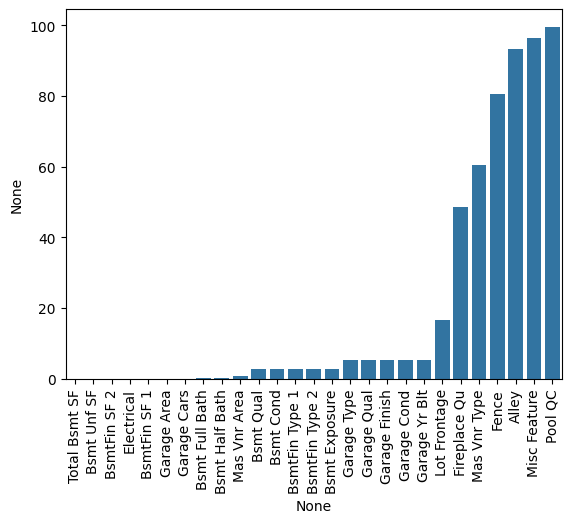

In [14]:
sns.barplot(x=percent_nan.index, y=percent_nan)
plt.xticks(rotation=90); # сейчас будем работать с отсутствующими данными которые не превышают 1 процент от всех данных

(0.0, 1.0)

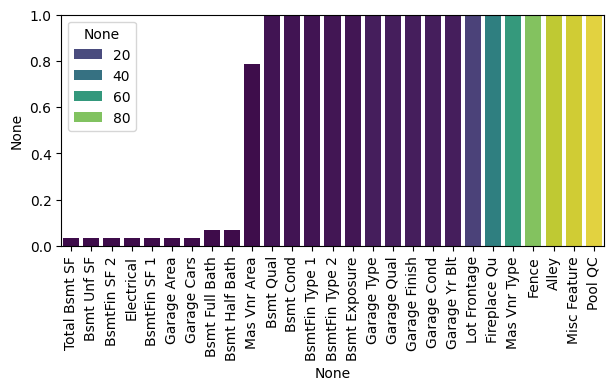

In [15]:
plt.figure(figsize=(7,3))
sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan, palette='viridis')
plt.xticks(rotation=90);
plt.ylim(0,1)

(0.0, 1.0)

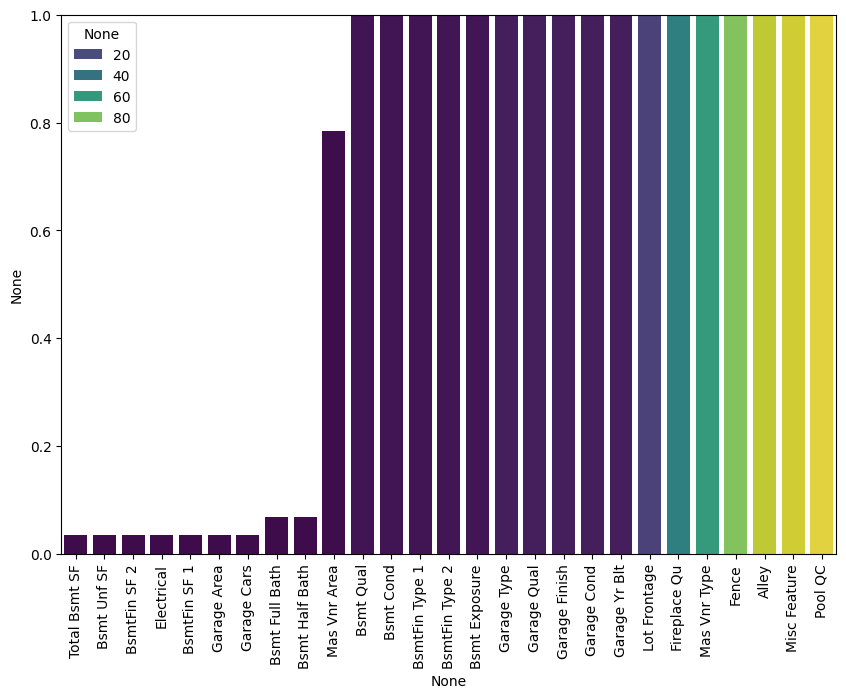

In [16]:
plt.figure(figsize=(10,7))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan, palette='viridis')
plt.xticks(rotation=90);
plt.ylim(0,1)

In [17]:
percent_nan[percent_nan < 1] 

Total Bsmt SF     0.034130
Bsmt Unf SF       0.034130
BsmtFin SF 2      0.034130
Electrical        0.034130
BsmtFin SF 1      0.034130
Garage Area       0.034130
Garage Cars       0.034130
Bsmt Full Bath    0.068259
Bsmt Half Bath    0.068259
Mas Vnr Area      0.784983
dtype: float64

In [18]:
100 / len(df) # тут мы видим что это значение всего навсего 1 строка в датафрейме, поэтому 

0.034129692832764506

In [19]:
df[df['Electrical'].isnull()]['Garage Area'] # покажи мне колонку Garage Area строки где электричество isnull = True

1577    400.0
Name: Garage Area, dtype: float64

In [20]:
df[df['Bsmt Half Bath'].isnull()]

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
1341,20,RM,99.0,5940,Pave,NaN,IR1,Lvl,AllPub,FR3,...,0,NaN,MnPrv,NaN,0,4,2008,ConLD,Abnorml,79000
1497,20,RL,123.0,47007,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,284700


In [21]:
df = df.dropna(axis=0, subset=['Electrical', 'Garage Area'])

In [22]:
percent_nan = percent_missing(df)

In [23]:
percent_nan[percent_nan < 1]

Total Bsmt SF     0.034153
Bsmt Unf SF       0.034153
BsmtFin SF 2      0.034153
BsmtFin SF 1      0.034153
Bsmt Full Bath    0.068306
Bsmt Half Bath    0.068306
Mas Vnr Area      0.785519
dtype: float64

(0.0, 1.0)

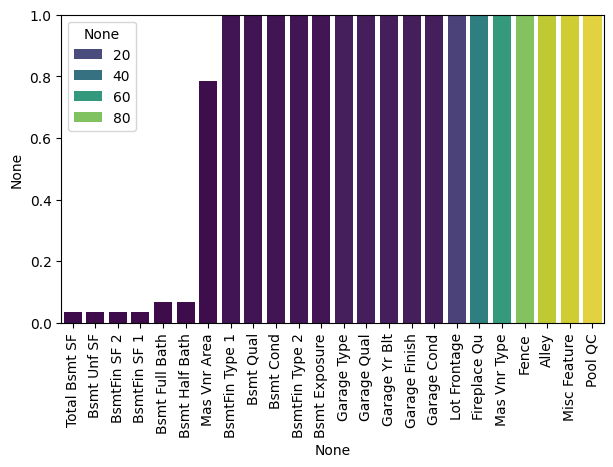

In [24]:
plt.figure(figsize=(7,4))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan, palette='viridis')
plt.xticks(rotation=90);
plt.ylim(0,1)

In [25]:
df[df['Bsmt Half Bath'].isnull()]

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
1341,20,RM,99.0,5940,Pave,NaN,IR1,Lvl,AllPub,FR3,...,0,NaN,MnPrv,NaN,0,4,2008,ConLD,Abnorml,79000
1497,20,RL,123.0,47007,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,284700


In [26]:
df[df['Bsmt Full Bath'].isnull()]

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
1341,20,RM,99.0,5940,Pave,NaN,IR1,Lvl,AllPub,FR3,...,0,NaN,MnPrv,NaN,0,4,2008,ConLD,Abnorml,79000
1497,20,RL,123.0,47007,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,284700


In [27]:
df[df['Bsmt Unf SF'].isnull()]

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
1341,20,RM,99.0,5940,Pave,NaN,IR1,Lvl,AllPub,FR3,...,0,NaN,MnPrv,NaN,0,4,2008,ConLD,Abnorml,79000


In [28]:
# для числовых колонок - fillna 0
bsmt_num_cols = ['BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF','Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath']
df[bsmt_num_cols] = df[bsmt_num_cols].fillna(0)
# для тесктовых колонок
bsmt_str_cols =  ['Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2']
df[bsmt_str_cols] = df[bsmt_str_cols].fillna('None')

In [29]:
df[df['Bsmt Full Bath'].isnull()] # как видим нет пустых значений в колонке

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice


In [30]:
percent_nan = percent_missing(df)

(0.0, 1.0)

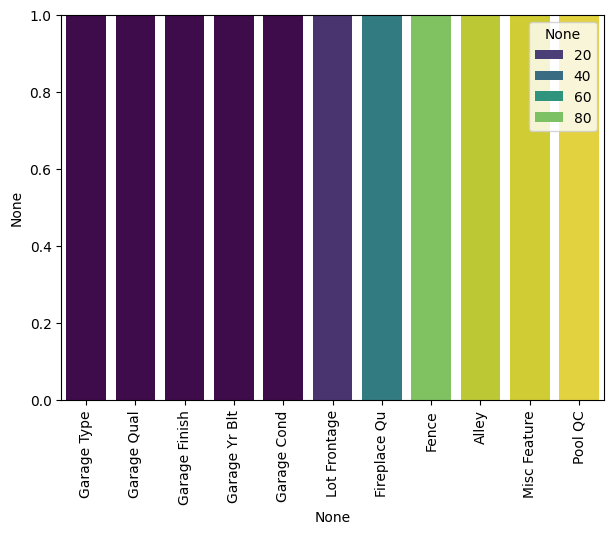

In [41]:
plt.figure(figsize=(7,5))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan, palette='viridis')
plt.xticks(rotation=90);
plt.ylim(0,1)

In [32]:
df['Mas Vnr Type'] = df['Mas Vnr Type'].fillna('None')

In [33]:
df['Mas Vnr Area'] = df['Mas Vnr Area'].fillna(0)

In [34]:
percent_nan = percent_missing(df)

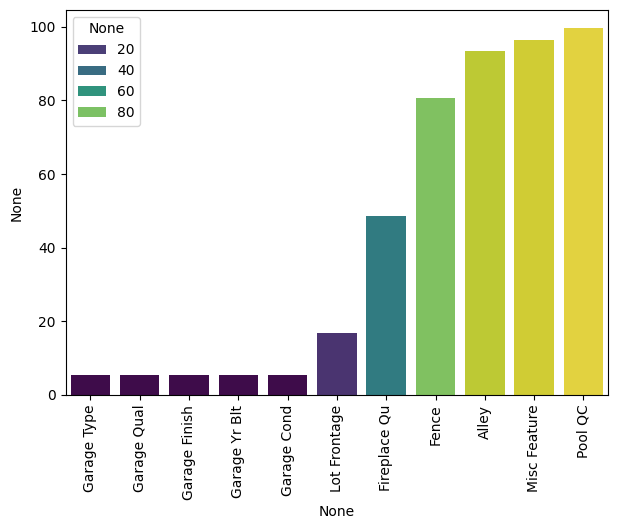

In [43]:
plt.figure(figsize=(7,5))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan, palette='viridis')
plt.xticks(rotation=90);

In [47]:
gar_str_cols = ['Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond']

In [48]:
df[gar_str_cols] = df[gar_str_cols].fillna('None')

In [50]:
percent_nan = percent_missing(df)

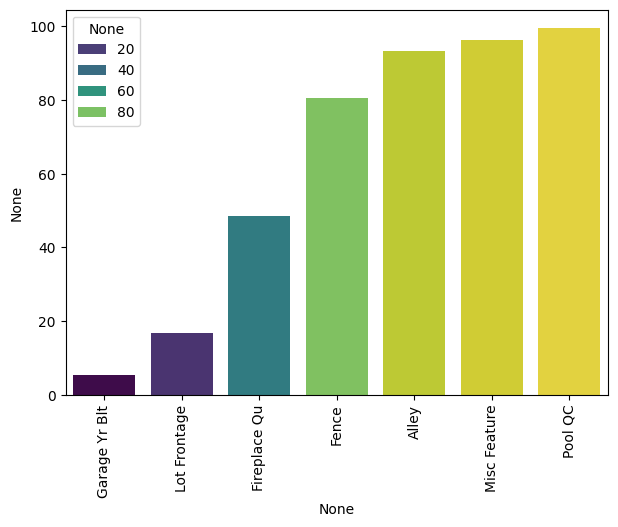

In [51]:
plt.figure(figsize=(7,5))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan, palette='viridis')
plt.xticks(rotation=90);

In [52]:
df['Garage Yr Blt'] = df['Garage Yr Blt'].fillna(0)

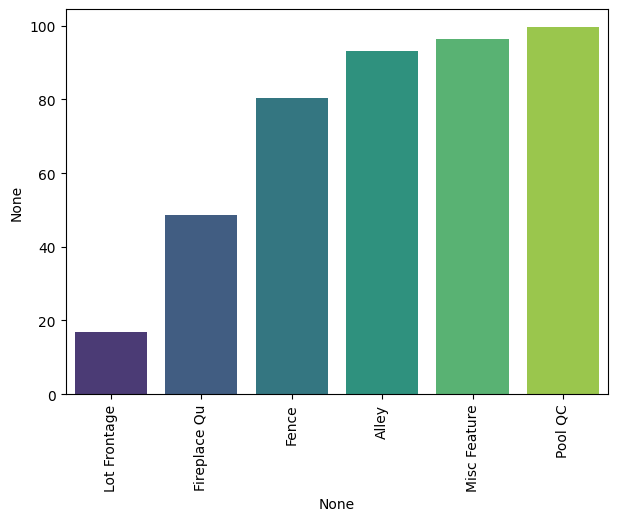

In [54]:
percent_nan = percent_missing(df)
plt.figure(figsize=(7,5))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan.index, palette='viridis')
plt.xticks(rotation=90);

In [56]:
df = df.drop(['Pool QC', 'Misc Feature', 'Alley', 'Fence'], axis=1)

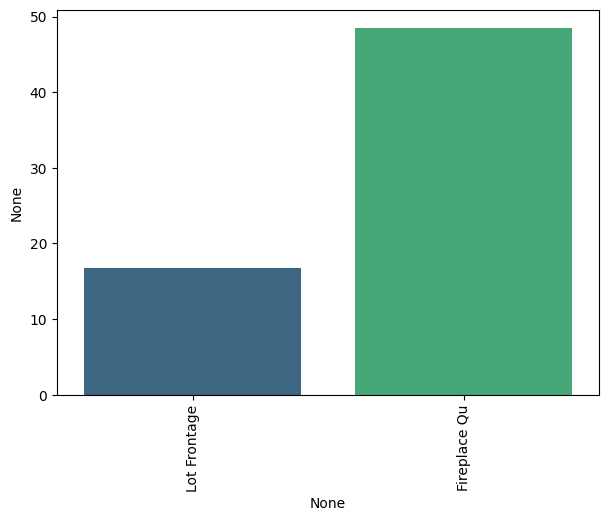

In [57]:
percent_nan = percent_missing(df)
plt.figure(figsize=(7,5))
ax = sns.barplot(x=percent_nan.index, y=percent_nan, hue=percent_nan.index, palette='viridis')
plt.xticks(rotation=90);

In [58]:
df['Fireplace Qu'].value_counts()

Fireplace Qu
Gd    744
TA    600
Fa     75
Po     46
Ex     43
Name: count, dtype: int64

In [59]:
df['Fireplace Qu'] = df['Fireplace Qu'].fillna('None')

In [60]:
df['Lot Frontage']

0       141.0
1        80.0
2        81.0
3        93.0
4        74.0
        ...  
2925     37.0
2926      NaN
2927     62.0
2928     77.0
2929     74.0
Name: Lot Frontage, Length: 2928, dtype: float64

<Axes: xlabel='Lot Frontage', ylabel='Neighborhood'>

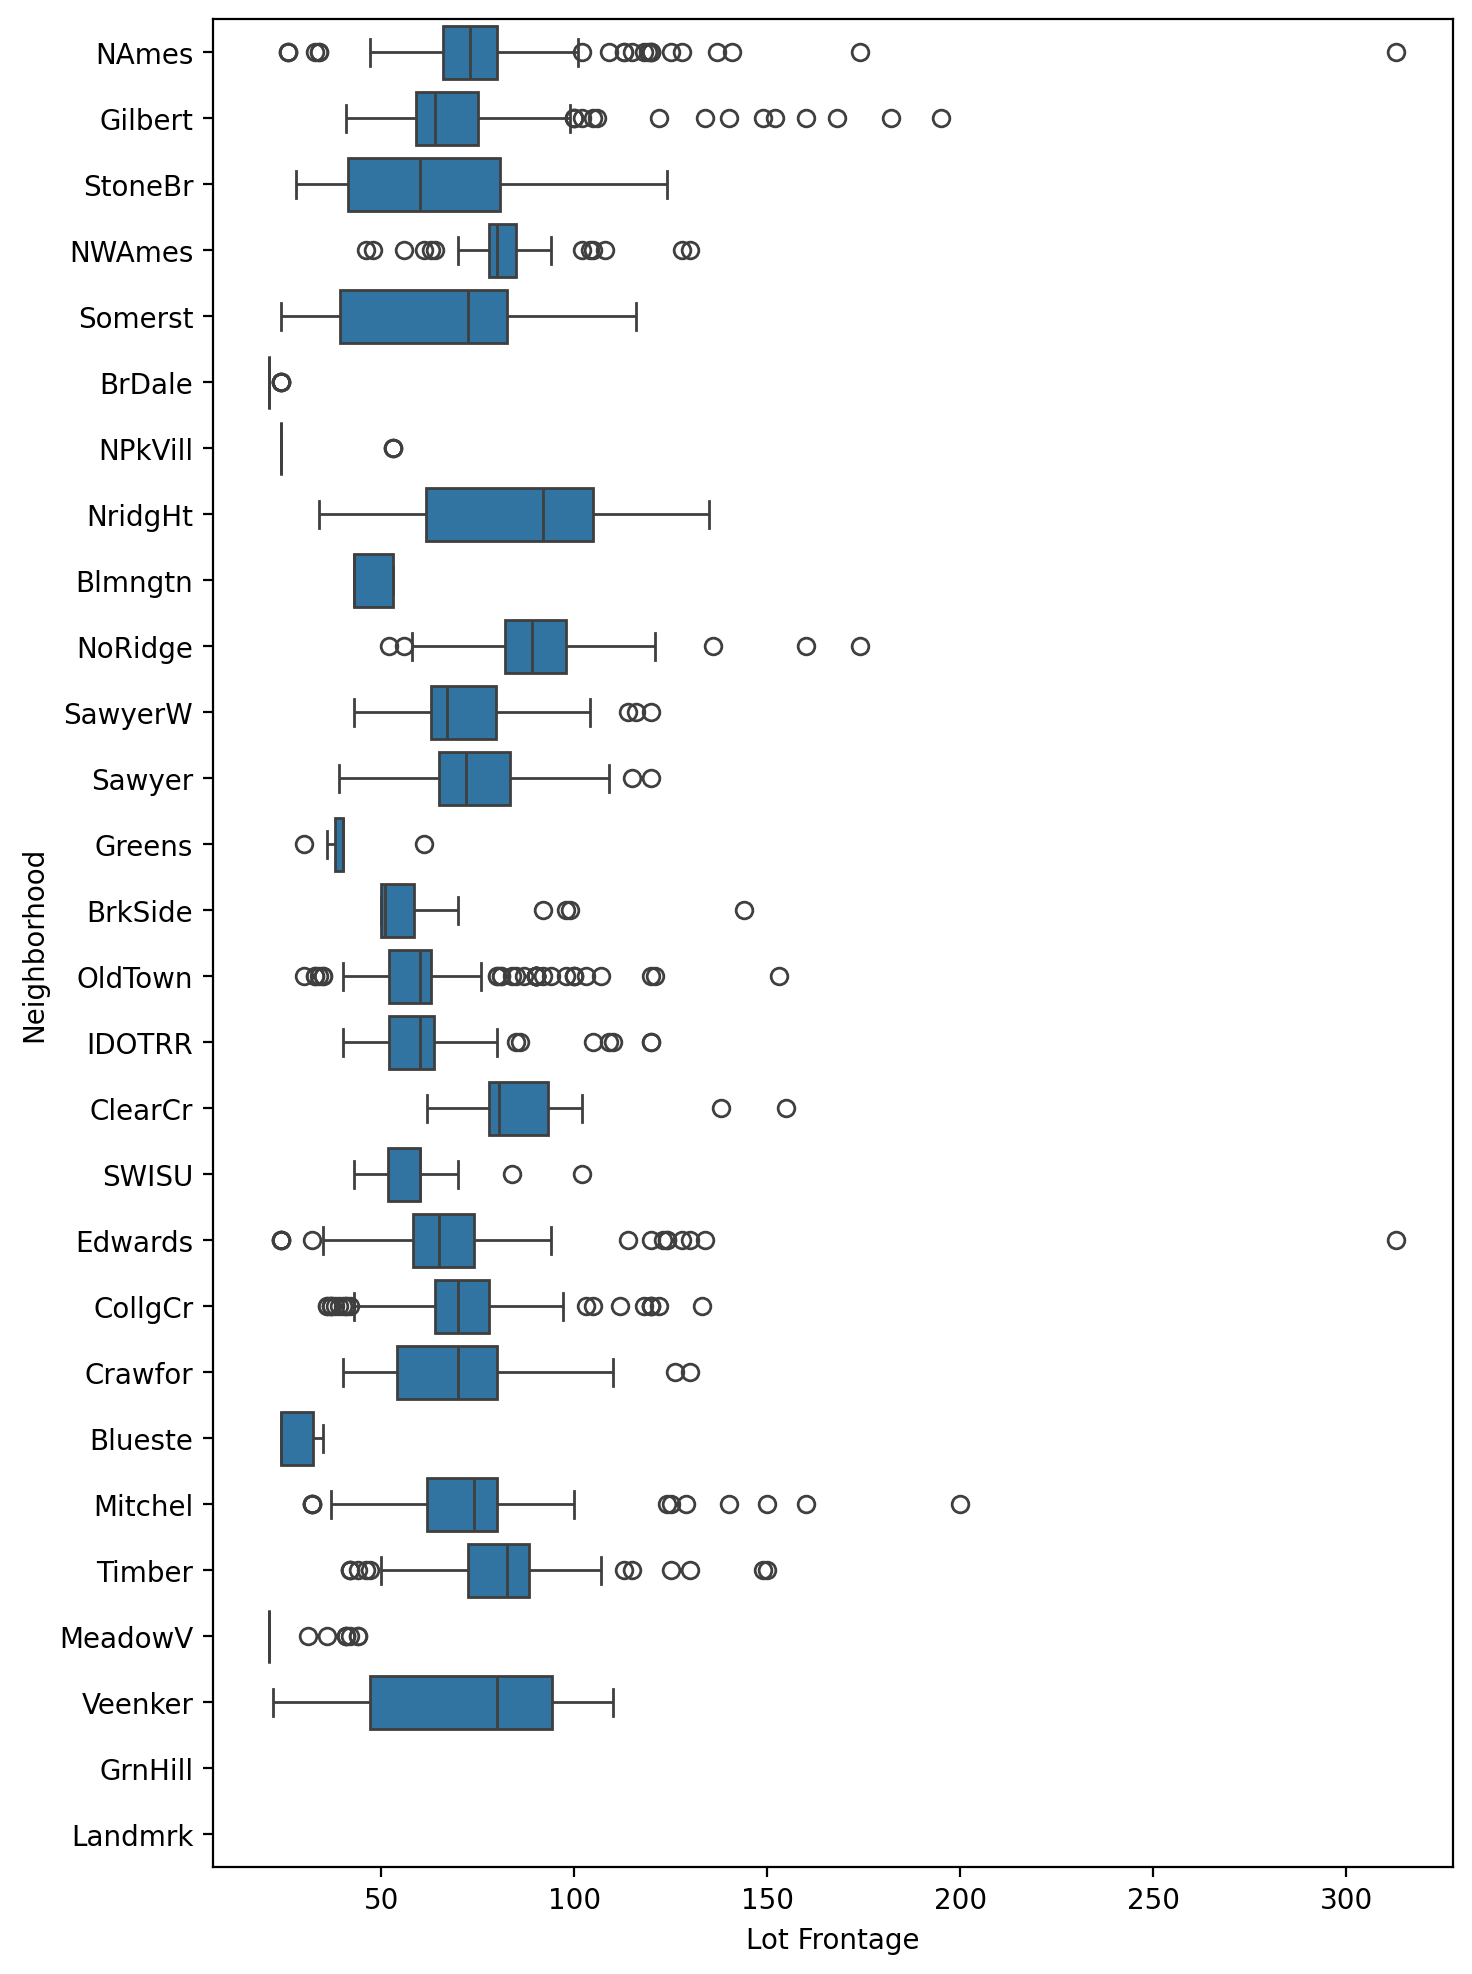

In [62]:
# Neighborhood
# LotFrontage
plt.figure(figsize=(8,12), dpi=200)
sns.boxplot(x='Lot Frontage', y='Neighborhood', data=df, orient='h')

In [63]:
df.groupby('Neighborhood')['Lot Frontage'].mean()

Neighborhood
Blmngtn    46.900000
Blueste    27.300000
BrDale     21.500000
BrkSide    55.789474
ClearCr    88.150000
CollgCr    71.336364
Crawfor    69.951807
Edwards    66.910112
Gilbert    74.207207
Greens     41.000000
GrnHill          NaN
IDOTRR     62.383721
Landmrk          NaN
MeadowV    25.606061
Mitchel    75.144444
NAmes      75.210667
NPkVill    28.142857
NWAmes     81.517647
NoRidge    91.629630
NridgHt    84.184049
OldTown    61.777293
SWISU      59.068182
Sawyer     74.551020
SawyerW    70.669811
Somerst    64.549383
StoneBr    62.173913
Timber     81.303571
Veenker    72.000000
Name: Lot Frontage, dtype: float64

In [65]:
df['Lot Frontage'] = df.groupby('Neighborhood')['Lot Frontage'].transform(lambda value: value.fillna(value.mean()))

In [67]:
df['Lot Frontage'].isnull().sum()

np.int64(3)

In [68]:
df['Lot Frontage'] = df['Lot Frontage'].fillna(0)

In [69]:
df['Lot Frontage'].isnull().sum()

np.int64(0)

In [70]:
percent_nan = percent_missing(df)

In [71]:
percent_nan

Series([], dtype: float64)

In [72]:
df.to_csv('Ames_Housing_Data_No_Missing_Data.csv')